<center>
    <img src="https://gitlab.com/ibm/skills-network/courses/placeholder101/-/raw/master/labs/module%201/images/IDSNlogo.png" width="300" alt="cognitiveclass.ai logo"  />
</center>


# SpaceX Falcon 9 First-Stage Landing Prediction


## Model comparison and evaluation


Estimated time needed: **60** minutes


Reusable first-stage boosters can reduce launch costs. This notebook explores whether historical launch characteristics are associated with recorded landing outcomes and compares several classification models. It is an educational, retrospective analysis—not an operational launch-safety system or a validated launch-pricing model.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing\_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


## Objectives

- Load the prepared launch and feature datasets from this repository.
- Define the recorded landing outcome as the target label.
- Split the data into training and test sets before fitting preprocessing steps.
- Tune classification models using cross-validation on training data only.
- Compare test-set performance using accuracy, precision, recall, F1-score, and confusion matrices.
- Discuss limitations, especially the small dataset and test set.


***


## Import Libraries and Define Auxiliary Functions


In [ ]:
!wget -q -O dataset_part_3.csv \
  https://raw.githubusercontent.com/olafisoyetope44-ship-it/Applied-Data-Capstone/main/dataset_part_3.csv

We will import the following libraries for the lab


In [31]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix
)

This function is to plot the confusion matrix.


In [32]:
def plot_confusion_matrix(y,y_predict):
    "this function plots the confusion matrix"
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y, y_predict)
    ax= plt.subplot()
    sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix');
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed'])

## Load the dataframe


Load the data


In [33]:
!wget -q -O dataset_part_2.csv \
  https://raw.githubusercontent.com/olafisoyetope44-ship-it/Applied-Data-Capstone/main/dataset_part_2.csv

In [34]:
data = pd.read_csv("dataset_part_2.csv")
data.head()


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [35]:
X = pd.read_csv("dataset_part_3.csv")

# Remove fields that can act as proxies for the observed outcome or memorise
# individual boosters. LandingPad is recorded after a landing attempt, and
# one-hot encoded serial numbers are high-cardinality identifiers with limited
# value for generalising to future launches.
excluded_prefixes = ("LandingPad_", "Serial_")
excluded_columns = [col for col in X.columns if col.startswith(excluded_prefixes)]
X = X.drop(columns=excluded_columns)

print(f"Features retained: {X.shape[1]}")
print(f"Excluded outcome-proxy/identifier features: {len(excluded_columns)}")
X.head()

Features retained: 20
Excluded outcome-proxy/identifier features: 56


,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_GEO,Orbit_GTO,Orbit_HEO,Orbit_ISS,Orbit_LEO,Orbit_MEO,Orbit_PO,Orbit_SO,Orbit_SSO,Orbit_VLEO,LaunchSite_KSC LC 39A,LaunchSite_VAFB SLC 4E
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## TASK  1


Create a NumPy array from the column <code>Class</code> in <code>data</code>, by applying the method <code>to_numpy()</code>  then
assign it  to the variable <code>Y</code>,make sure the output is a  Pandas series (only one bracket df\['name of  column']).


In [36]:
# target data as numpy array
Y = data['Class'].to_numpy()
Y

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1])

## TASK  2


Scaling is performed inside the model pipelines rather than before the split. This ensures that each cross-validation fold learns scaling parameters from its training portion only.

In [37]:
# Scaling will be fitted inside each cross-validation fold using a Pipeline.
# This prevents validation folds from influencing the scaling parameters.

The data is split into a training set and a held-out test set. Hyperparameters are selected using stratified five-fold cross-validation on the training set only. Scaling, where required, is part of each pipeline so it is refitted within every cross-validation fold.

## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


In [38]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2, stratify=Y
)

# Five stratified folds are a practical compromise for this small dataset.
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")
print(f"Training class counts: {pd.Series(Y_train).value_counts().sort_index().to_dict()}")
print(f"Test class counts: {pd.Series(Y_test).value_counts().sort_index().to_dict()}")

Training rows: 72; test rows: 18
Training class counts: {0: 24, 1: 48}
Test class counts: {0: 6, 1: 12}


we can see we only have 18 test samples.


In [39]:
Y_test.shape

(18,)

## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


### Logistic Regression

In [40]:
# StandardScaler is fitted separately within each CV training fold.
parameters_lr = {
    "model__C": [0.01, 0.1, 1],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"],
}
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=12345, max_iter=2000)),
])
grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=parameters_lr,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
)
logreg_cv = grid_search_lr.fit(X_train, Y_train)

We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [41]:
print("tuned hyperparameters :(best parameters) ",logreg_cv.best_params_)
print("accuracy :", logreg_cv.best_score_)

tuned hyperparameters :(best parameters)  {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
accuracy : 0.8228571428571427


## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


In [42]:
print('Accuracy on test data is: {:.3f}'.format(logreg_cv.score(X_test, Y_test)))

Accuracy on test data is: 0.833


Lets look at the confusion matrix:


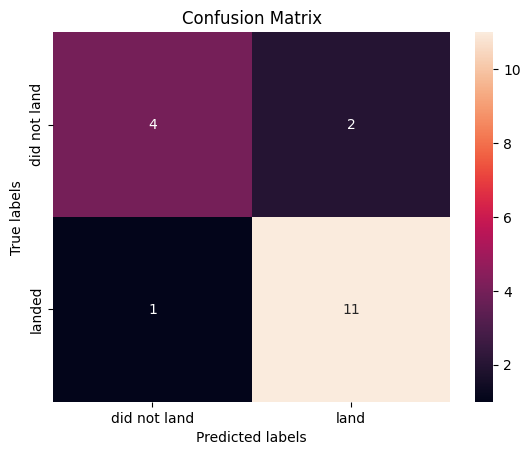

In [43]:
yhat_lr = logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat_lr)

The confusion matrix should be interpreted alongside precision, recall, and F1-score. With a small test set, a single prediction can noticeably change the reported metrics.


## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv - 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [44]:
parameters_svm = {
    "model__kernel": ["linear", "rbf", "poly", "sigmoid"],
    "model__C": np.logspace(-3, 3, 5),
    "model__gamma": np.logspace(-3, 3, 5),
}
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(random_state=12345)),
])
grid_search_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parameters_svm,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
)
svm_cv = grid_search_svm.fit(X_train, Y_train)

In [45]:
print("tuned hyperparameters :(best parameters) ",svm_cv.best_params_)
print("accuracy :",svm_cv.best_score_)

tuned hyperparameters :(best parameters)  {'model__C': np.float64(1.0), 'model__gamma': np.float64(0.001), 'model__kernel': 'linear'}
accuracy : 0.8361904761904763


## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


In [46]:
print('Accuracy on test data is: {:.3f}'.format(svm_cv.score(X_test, Y_test)))

Accuracy on test data is: 0.722


We can plot the confusion matrix


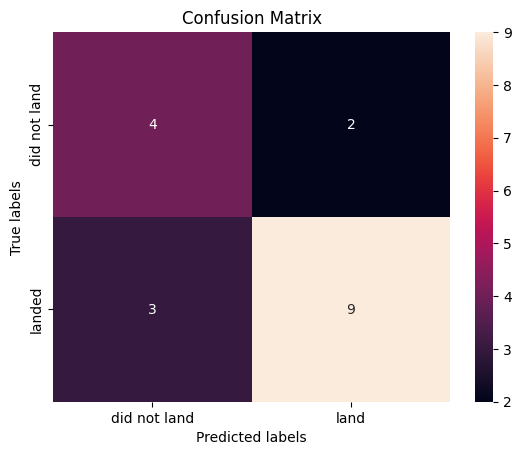

In [47]:
yhat_svm = svm_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat_svm)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [48]:
parameters_tree = {
    "criterion": ["gini", "entropy"],
    "splitter": ["best", "random"],
    "max_depth": [2*n for n in range(1, 10)],
    "max_features": ["sqrt", None],
    "min_samples_leaf": [1, 2, 4],
    "min_samples_split": [2, 5, 10],
}
tree = DecisionTreeClassifier(random_state=12345)
grid_search_tree = GridSearchCV(
    estimator=tree,
    param_grid=parameters_tree,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
)
tree_cv = grid_search_tree.fit(X_train, Y_train)

In [49]:
print("tuned hyperparameters :(best parameters) ",tree_cv.best_params_)
print("accuracy :",tree_cv.best_score_)

tuned hyperparameters :(best parameters)  {'criterion': 'gini', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'splitter': 'random'}
accuracy : 0.9057142857142857


## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


In [50]:
print('Accuracy on test data is: {:.3f}'.format(tree_cv.score(X_test, Y_test)))

Accuracy on test data is: 0.556


We can plot the confusion matrix


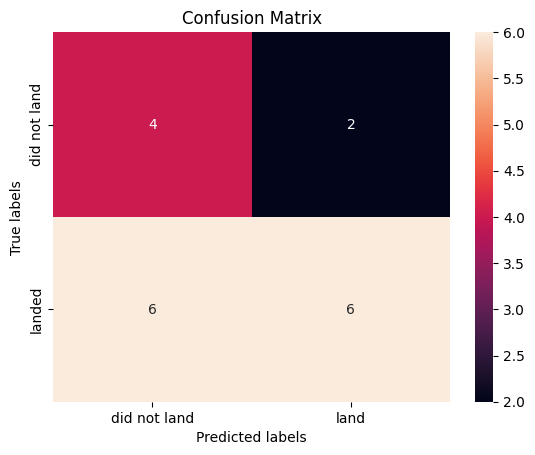

In [51]:
yhat_tree = tree_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat_tree)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [52]:
parameters_knn = {
    "model__n_neighbors": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier()),
])
grid_search_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=parameters_knn,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
)
knn_cv = grid_search_knn.fit(X_train, Y_train)

In [53]:
print("tuned hyperparameters :(best parameters) ",knn_cv.best_params_)
print("accuracy :",knn_cv.best_score_)

tuned hyperparameters :(best parameters)  {'model__n_neighbors': 8, 'model__p': 1, 'model__weights': 'uniform'}
accuracy : 0.8780952380952382


## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


In [54]:
print('Accuracy on test data is: {:.3f}'.format(knn_cv.score(X_test, Y_test)))

Accuracy on test data is: 0.722


We can plot the confusion matrix


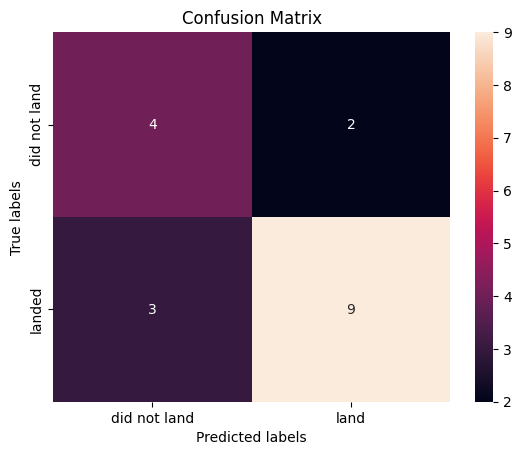

In [55]:
yhat_knn = knn_cv.predict(X_test)
plot_confusion_matrix(Y_test, yhat_knn)

## TASK  12


Find the method performs best:


In [56]:
models = {
    'KNeighbors': knn_cv.best_score_,
    'DecisionTree': tree_cv.best_score_,
    'LogisticRegression': logreg_cv.best_score_,
    'SupportVector': svm_cv.best_score_,
}
bestalgorithm = max(models, key=models.get)
print('Highest mean cross-validation accuracy:', bestalgorithm, f'({models[bestalgorithm]:.3f})')
print('This is a model-selection result on the training data, not a guarantee of future performance.')


Highest mean cross-validation accuracy: DecisionTree (0.906)
This is a model-selection result on the training data, not a guarantee of future performance.


## Final test-set evaluation

The grid searches above select hyperparameters using only the training split. The following cell evaluates each selected model once on the held-out test split. Review precision, recall, F1-score, and confusion-matrix counts as well as accuracy; the small sample means these estimates are uncertain.


In [57]:
best_models = {
    "Logistic Regression": logreg_cv.best_estimator_,
    "Support Vector Machine": svm_cv.best_estimator_,
    "Decision Tree": tree_cv.best_estimator_,
    "K-Nearest Neighbours": knn_cv.best_estimator_,
}

# Compare against a simple majority-class baseline.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, Y_train)
baseline_predictions = baseline.predict(X_test)
print(f"Majority-class baseline test accuracy: {accuracy_score(Y_test, baseline_predictions):.3f}")
print(f"Majority-class baseline balanced accuracy: {balanced_accuracy_score(Y_test, baseline_predictions):.3f}")

evaluation_rows = []
for model_name, model in best_models.items():
    predictions = model.predict(X_test)
    report = classification_report(Y_test, predictions, output_dict=True, zero_division=0)
    evaluation_rows.append({
        "Model": model_name,
        "CV accuracy (training folds)": {
            "Logistic Regression": logreg_cv.best_score_,
            "Support Vector Machine": svm_cv.best_score_,
            "Decision Tree": tree_cv.best_score_,
            "K-Nearest Neighbours": knn_cv.best_score_,
        }[model_name],
        "Test accuracy": accuracy_score(Y_test, predictions),
        "Test balanced accuracy": balanced_accuracy_score(Y_test, predictions),
        "Landing precision (class 1)": report["1"]["precision"],
        "Landing recall (class 1)": report["1"]["recall"],
        "Landing F1 (class 1)": report["1"]["f1-score"],
    })
    print(f"\n{model_name} — confusion matrix (rows=true, columns=predicted):")
    print(confusion_matrix(Y_test, predictions, labels=[0, 1]))
    print(classification_report(
        Y_test, predictions,
        labels=[0, 1],
        target_names=["Unsuccessful landing (0)", "Successful landing (1)"],
        zero_division=0,
    ))

evaluation = pd.DataFrame(evaluation_rows).sort_values(
    ["Test balanced accuracy", "Test accuracy"], ascending=False
)
evaluation.round(3)

Majority-class baseline test accuracy: 0.667
Majority-class baseline balanced accuracy: 0.500

Logistic Regression — confusion matrix (rows=true, columns=predicted):
[[ 4  2]
 [ 1 11]]
                          precision    recall  f1-score   support

Unsuccessful landing (0)       0.80      0.67      0.73         6
  Successful landing (1)       0.85      0.92      0.88        12

                accuracy                           0.83        18
               macro avg       0.82      0.79      0.80        18
            weighted avg       0.83      0.83      0.83        18


Support Vector Machine — confusion matrix (rows=true, columns=predicted):
[[4 2]
 [3 9]]
                          precision    recall  f1-score   support

Unsuccessful landing (0)       0.57      0.67      0.62         6
  Successful landing (1)       0.82      0.75      0.78        12

                accuracy                           0.72        18
               macro avg       0.69      0.71      0.70     

,Model,CV accuracy (training folds),Test accuracy,Test balanced accuracy,Landing precision (class 1),Landing recall (class 1),Landing F1 (class 1)
0,Logistic Regression,0.823,0.833,0.792,0.846,0.917,0.880
1,Support Vector Machine,0.836,0.722,0.708,0.818,0.750,0.783
3,K-Nearest Neighbours,0.878,0.722,0.708,0.818,0.750,0.783
2,Decision Tree,0.906,0.556,0.583,0.750,0.500,0.600


## Interpretation and limitations

- Compare the tuned models with the majority-class baseline; accuracy alone can be misleading when classes are imbalanced.
- The held-out test set contains only 18 launches, so all test metrics have high uncertainty.
- Scaling for Logistic Regression, SVM, and KNN is fitted inside each cross-validation fold using a pipeline.
- Landing-pad columns and individual booster serial-number columns are excluded because they may reveal post-outcome information or encourage memorisation rather than generalisation.
- Cross-validation results are for model selection; the held-out test set is reserved for final comparison.
- Results depend on the dataset snapshot, feature engineering, split, and library versions.
- Historical associations do not prove causation and should not be used alone for launch-safety or pricing decisions.

## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2021-01-01">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


## Change Log


| Date (YYYY-MM-DD) | Version | Changed By    | Change Description      |
| ----------------- | ------- | ------------- | ----------------------- |
| 2021-08-31        | 1.1     | Lakshmi Holla | Modified markdown       |
| 2020-09-20        | 1.0     | Joseph        | Modified Multiple Areas |


Copyright © 2020 IBM Corporation. All rights reserved.
